# ДЗ 3 · UCI Adult: від сирого файлу до SQL-аудиту

Навчальна робота з PostgreSQL 16: `COPY FROM STDIN`, окремі staging/clean-рівні й десять DQL-запитів. Аналізується початковий файл `adult.data`: **32 561 запис**, 14 ознак і мітка доходу. `adult.test` не використовується. Усі підрахунки незважені й описують цей історичний файл, а не населення США.

Ключовий результат SQL: три поля з пропусками, 24 надлишкові повні збіги записаних значень; жоден запис не видалено. Частка `income >50K` — 24,08%. Відсутній ідентифікатор особи, тому технічний номер рядка не доводить унікальності людей. Це описовий аудит; моделі й рішення щодо окремих людей тут не будуються.

## 1. Setup і перевірка PostgreSQL

Перша кодова секція встановлює зафіксовані залежності, запускає **окремий тимчасовий** кластер через `pgserver` і перевіряє major-версію 16. Для запуску потрібен Python 3.9+. Кластер не використовує навчальну Northwind чи будь-яку наявну БД. Повторний запуск створює новий кластер. Якщо виконання перервано, останню клітинку cleanup можна виконати окремо.

In [1]:
import sys, subprocess, importlib.metadata
required = {
    "pgserver": "0.1.4", "psycopg2-binary": "2.9.12",
    "SQLAlchemy": "2.0.54", "pandas": "2.3.3", "matplotlib": "3.9.4",
}
to_install = []
for package, version in required.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        to_install.append(f"{package}=={version}")
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])

from pathlib import Path
from tempfile import TemporaryDirectory
import atexit
import pgserver
from sqlalchemy import create_engine, text

hw3_tmp = TemporaryDirectory(prefix="hw3_adult_pg_")
pg = pgserver.get_server(Path(hw3_tmp.name) / "pgdata", cleanup_mode="stop")
engine = create_engine(pg.get_uri(), future=True)
with engine.connect() as conn:
    version = conn.execute(text("SELECT version() AS version")).scalar_one()
    version_num = int(conn.execute(text("SHOW server_version_num")).scalar_one())
assert version_num // 10000 == 16, f"Потрібен PostgreSQL 16, отримано: {version}"
print(version)
print("Python:", sys.version.split()[0])
print("Dependencies:", required)

def cleanup_hw3():
    engine.dispose()
    pg.cleanup()
    hw3_tmp.cleanup()

atexit.register(cleanup_hw3)

PostgreSQL 16.2 on aarch64-apple-darwin23.5.0, compiled by Apple clang version 15.0.0 (clang-1500.0.40.1), 64-bit
Python: 3.9.25
Dependencies: {'pgserver': '0.1.4', 'psycopg2-binary': '2.9.12', 'SQLAlchemy': '2.0.54', 'pandas': '2.3.3', 'matplotlib': '3.9.4'}


<function __main__.cleanup_hw3()>

## 2. Контекст, джерело і метод

Мета — перевірити, як відтворювано завантажити історичні спостереження та відповісти на десять описових запитань SQL. Офіційне джерело: [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult), Becker, B., & Kohavi, R. (1996), DOI [10.24432/C5XW20](https://doi.org/10.24432/C5XW20), ліцензія [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Дані походять із Census 1994. Офіційний ZIP і `adult.data` перевіряються SHA-256; за наявності локальної копії мережевий запит не потрібен.

### Ключові припущення

Зерно — один запис початкової навчальної частини. Добір уже зроблено авторами джерела; 48 842 на сторінці UCI — сума навчальної та тестової частин. У цій роботі немає довільного sampling, змішування частин чи дедуплікації. `fnlwgt` — фінальна вага опитування, а не ID; ваги збережено, але в описових частках вони не застосовуються. Категорії відображають історичний словник джерела. Асоціації не інтерпретуються як причини.

SQL виконує всю типізацію, аудит, фільтрацію й агрегацію. Python лише завантажує/перепаковує CSV, керує підключенням і показує вже обчислені SQL-результати.

In [2]:
import csv, hashlib, io, json, urllib.request, zipfile
from decimal import Decimal
import pandas as pd
from IPython.display import display, Markdown

cwd = Path.cwd()
# Пакет: notebook у deliverables/, дані й work/ поруч із README.md.
PROJECT_DIR = cwd.parent if cwd.name == "deliverables" else cwd
DATA_DIR = PROJECT_DIR / "data"
WORK_DIR = PROJECT_DIR / "work"
DATA_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
ZIP_SHA256 = "7537312dd56c2b98035880805ce99e68183a30ee468aa5329d6df0fbb3cc21bb"
RAW_SHA256 = "5b00264637dbfec36bdeaab5676b0b309ff9eb788d63554ca0a249491c86603d"
raw_path = DATA_DIR / "adult.data"
archive_path = DATA_DIR / "adult.zip"
if not raw_path.exists():
    if not archive_path.exists():
        with urllib.request.urlopen(SOURCE_URL, timeout=60) as response:
            archive_path.write_bytes(response.read())
    assert hashlib.sha256(archive_path.read_bytes()).hexdigest() == ZIP_SHA256
    with zipfile.ZipFile(archive_path) as archive:
        raw_path.write_bytes(archive.read("adult.data"))
        (DATA_DIR / "adult.names").write_bytes(archive.read("adult.names"))
raw_bytes = raw_path.read_bytes()
assert hashlib.sha256(raw_bytes).hexdigest() == RAW_SHA256, "Змінився офіційний вхід"

raw_columns = [
    "age_raw", "workclass_raw", "fnlwgt_raw", "education_raw", "education_num_raw",
    "marital_status_raw", "occupation_raw", "relationship_raw", "race_raw", "sex_raw",
    "capital_gain_raw", "capital_loss_raw", "hours_per_week_raw", "native_country_raw", "income_raw",
]
csv_path = DATA_DIR / "adult_train.csv"
row_count = 0
excluded_blank_lines = []
with csv_path.open("w", encoding="utf-8", newline="") as output:
    writer = csv.writer(output, quoting=csv.QUOTE_ALL, lineterminator="\n")
    writer.writerow(raw_columns)
    for line_no, line in enumerate(raw_bytes.decode("ascii").splitlines(), 1):
        if not line.strip():
            excluded_blank_lines.append(line_no)
            continue
        row = next(csv.reader([line], skipinitialspace=False))
        assert len(row) == 15, (line_no, len(row))
        writer.writerow(row)  # Значення не trim-имо; пробіли та ? збережено.
        row_count += 1
assert row_count == 32561
assert excluded_blank_lines == [32562]
print({"source": SOURCE_URL, "raw_sha256": RAW_SHA256, "records": row_count,
       "blank_lines_excluded": excluded_blank_lines,
       "csv_bytes": csv_path.stat().st_size,
       "csv_sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest()})

results = {}
def run_sql(key, sql):
    """Only database SELECT results are used for analysis; DataFrame is display-only."""
    display(Markdown("```sql\n" + sql.strip() + "\n```"))
    with engine.connect() as conn:
        result = conn.execute(text(sql))
        rows = [dict(row) for row in result.mappings()]
    frame = pd.DataFrame(rows)
    if key == "audit_null_sentinels":
        display(frame[["column_name", "question_marks", "clean_nulls", "pct_clean_null"]])
        display(frame[["column_name", "raw_sql_nulls", "empty_after_trim", "unknown_markers", "trimmed_values"]])
    elif len(rows) == 1 and len(frame.columns) > 6:
        display(frame.T.rename(columns={0: "value"}).rename_axis("metric"))
    else:
        display(frame)
    return rows

{'source': 'https://archive.ics.uci.edu/static/public/2/adult.zip', 'raw_sha256': '5b00264637dbfec36bdeaab5676b0b309ff9eb788d63554ca0a249491c86603d', 'records': 32561, 'blank_lines_excluded': [32562], 'csv_bytes': 4951380, 'csv_sha256': '80398fc53df713c9e4f4a5b96af7805146d9d2e607e0bf24aa65ae0f8207126c'}


Завершальний порожній рядок №32 562 не є спостереженням; він не потрапляє в контрольований CSV. Решта 32 561 рядка та порядок джерела збережені. CSV додає лише заголовок і quoting, а вихідний `adult.data` залишається незмінним. Усі 15 колонок staging мають `TEXT`; `source_rowid` — додаткова технічна позиція імпорту.

## 3. Staging, COPY та типізована таблиця

In [3]:
staging_sql = """
CREATE TABLE hw3_adult_staging (
    source_rowid BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    age_raw TEXT, workclass_raw TEXT, fnlwgt_raw TEXT,
    education_raw TEXT, education_num_raw TEXT, marital_status_raw TEXT,
    occupation_raw TEXT, relationship_raw TEXT, race_raw TEXT, sex_raw TEXT,
    capital_gain_raw TEXT, capital_loss_raw TEXT, hours_per_week_raw TEXT,
    native_country_raw TEXT, income_raw TEXT
);
"""
copy_sql = """
COPY hw3_adult_staging (
    age_raw, workclass_raw, fnlwgt_raw, education_raw, education_num_raw,
    marital_status_raw, occupation_raw, relationship_raw, race_raw, sex_raw,
    capital_gain_raw, capital_loss_raw, hours_per_week_raw, native_country_raw, income_raw
) FROM STDIN WITH (FORMAT CSV, HEADER MATCH, DELIMITER ',', ENCODING 'UTF8');
"""
display(Markdown("```sql\n" + staging_sql + "\n```"))
with engine.begin() as conn:
    conn.execute(text(staging_sql))
display(Markdown("```sql\n" + copy_sql + "\n```"))
raw_conn = engine.raw_connection()
try:
    with raw_conn.cursor() as cur:
        with csv_path.open("r", encoding="utf-8", newline="") as source:
            cur.copy_expert(copy_sql, source)
        copy_status = cur.statusmessage
    raw_conn.commit()
finally:
    raw_conn.close()
print(copy_status)
results["loaded"] = run_sql("loaded", "SELECT COUNT(*) AS loaded_rows FROM hw3_adult_staging")
assert results["loaded"][0]["loaded_rows"] == row_count

```sql

CREATE TABLE hw3_adult_staging (
    source_rowid BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    age_raw TEXT, workclass_raw TEXT, fnlwgt_raw TEXT,
    education_raw TEXT, education_num_raw TEXT, marital_status_raw TEXT,
    occupation_raw TEXT, relationship_raw TEXT, race_raw TEXT, sex_raw TEXT,
    capital_gain_raw TEXT, capital_loss_raw TEXT, hours_per_week_raw TEXT,
    native_country_raw TEXT, income_raw TEXT
);

```

```sql

COPY hw3_adult_staging (
    age_raw, workclass_raw, fnlwgt_raw, education_raw, education_num_raw,
    marital_status_raw, occupation_raw, relationship_raw, race_raw, sex_raw,
    capital_gain_raw, capital_loss_raw, hours_per_week_raw, native_country_raw, income_raw
) FROM STDIN WITH (FORMAT CSV, HEADER MATCH, DELIMITER ',', ENCODING 'UTF8');

```

```sql
SELECT COUNT(*) AS loaded_rows FROM hw3_adult_staging
```

,loaded_rows
0,32561


### Словник колонок і правила типізації

Джерело — `adult.names` з офіційного [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult). Порядок нижче відповідає 15 полям `adult.data`. У staging кожна джерельна колонка має тип `TEXT` і суфікс `_raw`; це зберігає пробіли й маркери до SQL-перетворення. У таблиці clean усі крайові пробіли прибираються `BTRIM`, після чого виконуються явні приведення типів. Рядки не відкидаються.

| Позиція / raw-колонка | Семантика й формат джерела | Колонка clean / тип PostgreSQL | Очищення й обмеження |
| --- | --- | --- | --- |
| 1 · `age_raw` | Вік, десяткова ціла лексема; UCI позначає ознаку як continuous | `age SMALLINT NOT NULL` | `BTRIM(...)::SMALLINT`; `CHECK (age BETWEEN 17 AND 120)` |
| 2 · `workclass_raw` | Категорія зайнятості / тип роботодавця; текст або `?` | `workclass TEXT` | `NULLIF(BTRIM(...), '?')`; NULL дозволено, порожня категорія заборонена |
| 3 · `fnlwgt_raw` | Final weight — фінальна вага опитування CPS, ціла лексема | `fnlwgt INTEGER NOT NULL` | Явний cast після trim; `CHECK (fnlwgt > 0)`; це не ID людини |
| 4 · `education_raw` | Текстова категорія освіти | `education TEXT NOT NULL` | `BTRIM(...)`; порожнє значення заборонене; категорії збережено як у джерелі |
| 5 · `education_num_raw` | Числове кодування рівня освіти, ціла лексема | `education_num SMALLINT NOT NULL` | Явний cast; `CHECK (education_num BETWEEN 1 AND 16)` |
| 6 · `marital_status_raw` | Категорія сімейного стану | `marital_status TEXT NOT NULL` | `BTRIM(...)`; порожнє значення заборонене |
| 7 · `occupation_raw` | Категорія професії; текст або `?` | `occupation TEXT` | `NULLIF(BTRIM(...), '?')`; NULL дозволено, порожня категорія заборонена |
| 8 · `relationship_raw` | Категорія відносин у домогосподарстві | `relationship TEXT NOT NULL` | `BTRIM(...)`; порожнє значення заборонене |
| 9 · `race_raw` | Історична категорія race у словнику набору | `race TEXT NOT NULL` | `BTRIM(...)`; оригінальні назви збережено; порожнє значення заборонене |
| 10 · `sex_raw` | Категорія sex; джерельні значення Female / Male | `sex TEXT NOT NULL` | `BTRIM(...)`; це збережена категорія, тому її не перетворено механічно на BOOLEAN |
| 11 · `capital_gain_raw` | Показник capital gain, ціла невід'ємна лексема | `capital_gain NUMERIC(9,0) NOT NULL` | Явний cast після trim; `CHECK (capital_gain >= 0)` |
| 12 · `capital_loss_raw` | Показник capital loss, ціла невід'ємна лексема | `capital_loss NUMERIC(9,0) NOT NULL` | Явний cast після trim; `CHECK (capital_loss >= 0)` |
| 13 · `hours_per_week_raw` | Кількість робочих годин на тиждень, ціла лексема | `hours_per_week SMALLINT NOT NULL` | Явний cast; `CHECK (hours_per_week BETWEEN 1 AND 168)` |
| 14 · `native_country_raw` | Категорія країни походження; текст або `?` | `native_country TEXT` | `NULLIF(BTRIM(...), '?')`; NULL дозволено; історичні назви не виправляються без підстав |
| 15 · `income_raw` | Річний дохід у двох категоріях: `>50K` / `<=50K`; точного доходу немає | `income_gt_50k BOOLEAN NOT NULL` | Після trim лише `>50K → TRUE`, `<=50K → FALSE`; попередня SQL-перевірка відхиляє будь-яку іншу мітку |
| Технічна · `source_rowid` | Позиція запису під час послідовного COPY; не джерельна ознака | `BIGINT`, у staging `GENERATED ALWAYS AS IDENTITY PRIMARY KEY`, у clean `PRIMARY KEY` | Переноситься без зміни; ідентифікує запис конкретного файлу, а не особу |

`SMALLINT` достатній для віку, коду освіти й годин; `INTEGER` зберігає спостережені ваги без втрат. Для капітальних грошових показників обрано точний `NUMERIC(9,0)`: у файлі немає дробової частини, тому масштаб 0 не вигадує центів. Точну одиницю й період цих двох полів `adult.names` окремо не пояснює. Числа з дробовою частиною не слід додавати до джерела без нового контракту парсингу.

`TEXT` доречний для категорій без установленого бізнес-ліміту довжини; довільний `VARCHAR(255)` нічого не обґрунтовує. `DATE` та `TIMESTAMPTZ` тут не застосовано: спостереження не містять дат або моментів подій. Дата завантаження була б лише технічною метаданою і не замінила б дату вимірювання.

Межа віку 120 є консервативним припущенням цього контракту, а не документованою верхньою межею UCI; 168 годин — фізична тривалість тижня. `CHECK` перевіряє прийнятність значення за обраним правилом, а не правдивість повідомленого факту. `NOT NULL` задається окремо: сам `CHECK` не забороняє SQL NULL.

Спеціальний маркер `?` нормалізується до SQL NULL лише в трьох документованих полях: workclass, occupation, native_country. Сира лексема ` ?` має пробіл, тому `COPY ... NULL '?'` не замінив би SQL-очищення. Порожні лексеми й `unknown` перевіряються окремо; ця робота не створює штучних пропусків і не підміняє невідоме значення реальною категорією. Початковий income залишається відновлюваним у staging; його BOOLEAN-версія є цільовою змінною, а не додатковою ознакою.

In [4]:
ddl_sql = """
CREATE TABLE hw3_adult_clean (
    source_rowid BIGINT PRIMARY KEY,
    age SMALLINT NOT NULL CHECK (age BETWEEN 17 AND 120),
    workclass TEXT,
    fnlwgt INTEGER NOT NULL CHECK (fnlwgt > 0),
    education TEXT NOT NULL CHECK (LENGTH(education) > 0),
    education_num SMALLINT NOT NULL CHECK (education_num BETWEEN 1 AND 16),
    marital_status TEXT NOT NULL CHECK (LENGTH(marital_status) > 0),
    occupation TEXT,
    relationship TEXT NOT NULL CHECK (LENGTH(relationship) > 0),
    race TEXT NOT NULL CHECK (LENGTH(race) > 0),
    sex TEXT NOT NULL CHECK (LENGTH(sex) > 0),
    capital_gain NUMERIC(9,0) NOT NULL CHECK (capital_gain >= 0),
    capital_loss NUMERIC(9,0) NOT NULL CHECK (capital_loss >= 0),
    hours_per_week SMALLINT NOT NULL CHECK (hours_per_week BETWEEN 1 AND 168),
    native_country TEXT,
    income_gt_50k BOOLEAN NOT NULL,
    CHECK (workclass IS NULL OR LENGTH(workclass) > 0),
    CHECK (occupation IS NULL OR LENGTH(occupation) > 0),
    CHECK (native_country IS NULL OR LENGTH(native_country) > 0)
);

-- Fail closed: невідома мітка не стає FALSE і не відкидається.
DO $$
BEGIN
    IF EXISTS (
        SELECT 1 FROM hw3_adult_staging
        WHERE income_raw IS NULL OR BTRIM(income_raw) NOT IN ('>50K', '<=50K')
    ) THEN
        RAISE EXCEPTION 'Unexpected income label';
    END IF;
END $$;
"""
insert_sql = """
INSERT INTO hw3_adult_clean (
    source_rowid, age, workclass, fnlwgt, education, education_num, marital_status,
    occupation, relationship, race, sex, capital_gain, capital_loss,
    hours_per_week, native_country, income_gt_50k
)
SELECT
    source_rowid,
    BTRIM(age_raw)::SMALLINT,
    NULLIF(BTRIM(workclass_raw), '?'),
    BTRIM(fnlwgt_raw)::INTEGER,
    BTRIM(education_raw),
    BTRIM(education_num_raw)::SMALLINT,
    BTRIM(marital_status_raw),
    NULLIF(BTRIM(occupation_raw), '?'),
    BTRIM(relationship_raw),
    BTRIM(race_raw),
    BTRIM(sex_raw),
    BTRIM(capital_gain_raw)::NUMERIC(9,0),
    BTRIM(capital_loss_raw)::NUMERIC(9,0),
    BTRIM(hours_per_week_raw)::SMALLINT,
    NULLIF(BTRIM(native_country_raw), '?'),
    CASE BTRIM(income_raw) WHEN '>50K' THEN TRUE WHEN '<=50K' THEN FALSE ELSE NULL END
FROM hw3_adult_staging
ORDER BY source_rowid;
"""
display(Markdown("```sql\n" + ddl_sql + insert_sql + "\n```"))
with engine.begin() as conn:
    conn.execute(text(ddl_sql))
    inserted = conn.execute(text(insert_sql)).rowcount
print("Inserted:", inserted)
assert inserted == 32561

```sql

CREATE TABLE hw3_adult_clean (
    source_rowid BIGINT PRIMARY KEY,
    age SMALLINT NOT NULL CHECK (age BETWEEN 17 AND 120),
    workclass TEXT,
    fnlwgt INTEGER NOT NULL CHECK (fnlwgt > 0),
    education TEXT NOT NULL CHECK (LENGTH(education) > 0),
    education_num SMALLINT NOT NULL CHECK (education_num BETWEEN 1 AND 16),
    marital_status TEXT NOT NULL CHECK (LENGTH(marital_status) > 0),
    occupation TEXT,
    relationship TEXT NOT NULL CHECK (LENGTH(relationship) > 0),
    race TEXT NOT NULL CHECK (LENGTH(race) > 0),
    sex TEXT NOT NULL CHECK (LENGTH(sex) > 0),
    capital_gain NUMERIC(9,0) NOT NULL CHECK (capital_gain >= 0),
    capital_loss NUMERIC(9,0) NOT NULL CHECK (capital_loss >= 0),
    hours_per_week SMALLINT NOT NULL CHECK (hours_per_week BETWEEN 1 AND 168),
    native_country TEXT,
    income_gt_50k BOOLEAN NOT NULL,
    CHECK (workclass IS NULL OR LENGTH(workclass) > 0),
    CHECK (occupation IS NULL OR LENGTH(occupation) > 0),
    CHECK (native_country IS NULL OR LENGTH(native_country) > 0)
);

-- Fail closed: невідома мітка не стає FALSE і не відкидається.
DO $$
BEGIN
    IF EXISTS (
        SELECT 1 FROM hw3_adult_staging
        WHERE income_raw IS NULL OR BTRIM(income_raw) NOT IN ('>50K', '<=50K')
    ) THEN
        RAISE EXCEPTION 'Unexpected income label';
    END IF;
END $$;

INSERT INTO hw3_adult_clean (
    source_rowid, age, workclass, fnlwgt, education, education_num, marital_status,
    occupation, relationship, race, sex, capital_gain, capital_loss,
    hours_per_week, native_country, income_gt_50k
)
SELECT
    source_rowid,
    BTRIM(age_raw)::SMALLINT,
    NULLIF(BTRIM(workclass_raw), '?'),
    BTRIM(fnlwgt_raw)::INTEGER,
    BTRIM(education_raw),
    BTRIM(education_num_raw)::SMALLINT,
    BTRIM(marital_status_raw),
    NULLIF(BTRIM(occupation_raw), '?'),
    BTRIM(relationship_raw),
    BTRIM(race_raw),
    BTRIM(sex_raw),
    BTRIM(capital_gain_raw)::NUMERIC(9,0),
    BTRIM(capital_loss_raw)::NUMERIC(9,0),
    BTRIM(hours_per_week_raw)::SMALLINT,
    NULLIF(BTRIM(native_country_raw), '?'),
    CASE BTRIM(income_raw) WHEN '>50K' THEN TRUE WHEN '<=50K' THEN FALSE ELSE NULL END
FROM hw3_adult_staging
ORDER BY source_rowid;

```

Inserted: 32561


## 4. Data-quality audit

### 4.1. Кількість рядків і збереження записів

In [5]:
results['audit_counts'] = run_sql('audit_counts', """
SELECT 'staging' AS layer, COUNT(*) AS n_rows FROM hw3_adult_staging
UNION ALL
SELECT 'clean' AS layer, COUNT(*) AS n_rows FROM hw3_adult_clean
ORDER BY layer;
""")

```sql
SELECT 'staging' AS layer, COUNT(*) AS n_rows FROM hw3_adult_staging
UNION ALL
SELECT 'clean' AS layer, COUNT(*) AS n_rows FROM hw3_adult_clean
ORDER BY layer;
```

,layer,n_rows
0,clean,32561
1,staging,32561


Обидва рівні мають 32 561 запис. `INSERT ... SELECT` не має `WHERE`: жоден запис не відфільтровано; змінюються лише представлення пробілів, пропусків, чисел і мітки. Порожній завершальний рядок файла виключений до staging, оскільки не має 15 полів.

### 4.2. Збіги значень і відсутність природного ключа

У файлі немає гарантованого business key особи. Найсильніша доступна комбінація — усі 15 початкових значень; вона перевіряє **повний збіг запису**, а не ідентичність людини. Технічний `source_rowid` навмисно виключено з комбінації.

In [6]:
results['audit_duplicates'] = run_sql('audit_duplicates', """
WITH duplicate_groups AS (
    SELECT age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income_gt_50k, COUNT(*) AS group_size
    FROM hw3_adult_clean
    GROUP BY age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income_gt_50k
    HAVING COUNT(*) > 1
)
SELECT
    (SELECT COUNT(*) FROM hw3_adult_clean) AS total_rows,
    (SELECT COUNT(DISTINCT (age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income_gt_50k)) FROM hw3_adult_clean) AS distinct_record_values,
    COUNT(*) AS duplicate_groups,
    COALESCE(SUM(group_size), 0)::BIGINT AS rows_in_duplicate_groups,
    COALESCE(SUM(group_size - 1), 0)::BIGINT AS excess_duplicate_rows
FROM duplicate_groups;
""")

```sql
WITH duplicate_groups AS (
    SELECT age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income_gt_50k, COUNT(*) AS group_size
    FROM hw3_adult_clean
    GROUP BY age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income_gt_50k
    HAVING COUNT(*) > 1
)
SELECT
    (SELECT COUNT(*) FROM hw3_adult_clean) AS total_rows,
    (SELECT COUNT(DISTINCT (age, workclass, fnlwgt, education, education_num, marital_status, occupation, relationship, race, sex, capital_gain, capital_loss, hours_per_week, native_country, income_gt_50k)) FROM hw3_adult_clean) AS distinct_record_values,
    COUNT(*) AS duplicate_groups,
    COALESCE(SUM(group_size), 0)::BIGINT AS rows_in_duplicate_groups,
    COALESCE(SUM(group_size - 1), 0)::BIGINT AS excess_duplicate_rows
FROM duplicate_groups;
```

,total_rows,distinct_record_values,duplicate_groups,rows_in_duplicate_groups,excess_duplicate_rows
0,32561,32537,23,47,24


32 537 різних комбінацій дають 23 групи повторів: у них 47 рядків, з яких 24 — надлишкові повні збіги. Це не 24 доведено повторно опитані особи. Усі рядки збережено; для майбутнього ML split треба окремо перевірити, чи однакові профілі не потрапляють у різні частини.

### 4.3. Сирі маркери й фактичні NULL

Перевіряються всі 15 полів, включно з `?`, порожнім текстом, `unknown`, SQL NULL і змінами після `BTRIM`. Це розрізняє спеціальний маркер від відсутнього SQL-значення.

In [7]:
results['audit_null_sentinels'] = run_sql('audit_null_sentinels', """
WITH raw_audit AS (
    SELECT v.column_name,
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE v.raw_value IS NULL) AS raw_sql_nulls,
        COUNT(*) FILTER (WHERE BTRIM(v.raw_value) = '?') AS question_marks,
        COUNT(*) FILTER (WHERE BTRIM(v.raw_value) = '') AS empty_after_trim,
        COUNT(*) FILTER (WHERE LOWER(BTRIM(v.raw_value)) = 'unknown') AS unknown_markers,
        COUNT(*) FILTER (WHERE v.raw_value IS DISTINCT FROM BTRIM(v.raw_value)) AS trimmed_values
    FROM hw3_adult_staging AS s
    CROSS JOIN LATERAL (VALUES
        ('age', s.age_raw),
        ('workclass', s.workclass_raw),
        ('fnlwgt', s.fnlwgt_raw),
        ('education', s.education_raw),
        ('education_num', s.education_num_raw),
        ('marital_status', s.marital_status_raw),
        ('occupation', s.occupation_raw),
        ('relationship', s.relationship_raw),
        ('race', s.race_raw),
        ('sex', s.sex_raw),
        ('capital_gain', s.capital_gain_raw),
        ('capital_loss', s.capital_loss_raw),
        ('hours_per_week', s.hours_per_week_raw),
        ('native_country', s.native_country_raw),
        ('income_gt_50k', s.income_raw)
    ) AS v(column_name, raw_value)
    GROUP BY v.column_name
), clean_audit AS (
    SELECT v.column_name, COUNT(*) FILTER (WHERE v.clean_value IS NULL) AS clean_nulls
    FROM hw3_adult_clean AS c
    CROSS JOIN LATERAL (VALUES
        ('age', c.age::TEXT),
        ('workclass', c.workclass::TEXT),
        ('fnlwgt', c.fnlwgt::TEXT),
        ('education', c.education::TEXT),
        ('education_num', c.education_num::TEXT),
        ('marital_status', c.marital_status::TEXT),
        ('occupation', c.occupation::TEXT),
        ('relationship', c.relationship::TEXT),
        ('race', c.race::TEXT),
        ('sex', c.sex::TEXT),
        ('capital_gain', c.capital_gain::TEXT),
        ('capital_loss', c.capital_loss::TEXT),
        ('hours_per_week', c.hours_per_week::TEXT),
        ('native_country', c.native_country::TEXT),
        ('income_gt_50k', c.income_gt_50k::TEXT)
    ) AS v(column_name, clean_value)
    GROUP BY v.column_name
)
SELECT r.column_name, r.total_rows, r.raw_sql_nulls, r.question_marks,
       r.empty_after_trim, r.unknown_markers, r.trimmed_values, c.clean_nulls,
       ROUND(c.clean_nulls * 100.0 / NULLIF(r.total_rows, 0), 2) AS pct_clean_null
FROM raw_audit AS r
JOIN clean_audit AS c USING (column_name)
ORDER BY r.column_name;
""")

```sql
WITH raw_audit AS (
    SELECT v.column_name,
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE v.raw_value IS NULL) AS raw_sql_nulls,
        COUNT(*) FILTER (WHERE BTRIM(v.raw_value) = '?') AS question_marks,
        COUNT(*) FILTER (WHERE BTRIM(v.raw_value) = '') AS empty_after_trim,
        COUNT(*) FILTER (WHERE LOWER(BTRIM(v.raw_value)) = 'unknown') AS unknown_markers,
        COUNT(*) FILTER (WHERE v.raw_value IS DISTINCT FROM BTRIM(v.raw_value)) AS trimmed_values
    FROM hw3_adult_staging AS s
    CROSS JOIN LATERAL (VALUES
        ('age', s.age_raw),
        ('workclass', s.workclass_raw),
        ('fnlwgt', s.fnlwgt_raw),
        ('education', s.education_raw),
        ('education_num', s.education_num_raw),
        ('marital_status', s.marital_status_raw),
        ('occupation', s.occupation_raw),
        ('relationship', s.relationship_raw),
        ('race', s.race_raw),
        ('sex', s.sex_raw),
        ('capital_gain', s.capital_gain_raw),
        ('capital_loss', s.capital_loss_raw),
        ('hours_per_week', s.hours_per_week_raw),
        ('native_country', s.native_country_raw),
        ('income_gt_50k', s.income_raw)
    ) AS v(column_name, raw_value)
    GROUP BY v.column_name
), clean_audit AS (
    SELECT v.column_name, COUNT(*) FILTER (WHERE v.clean_value IS NULL) AS clean_nulls
    FROM hw3_adult_clean AS c
    CROSS JOIN LATERAL (VALUES
        ('age', c.age::TEXT),
        ('workclass', c.workclass::TEXT),
        ('fnlwgt', c.fnlwgt::TEXT),
        ('education', c.education::TEXT),
        ('education_num', c.education_num::TEXT),
        ('marital_status', c.marital_status::TEXT),
        ('occupation', c.occupation::TEXT),
        ('relationship', c.relationship::TEXT),
        ('race', c.race::TEXT),
        ('sex', c.sex::TEXT),
        ('capital_gain', c.capital_gain::TEXT),
        ('capital_loss', c.capital_loss::TEXT),
        ('hours_per_week', c.hours_per_week::TEXT),
        ('native_country', c.native_country::TEXT),
        ('income_gt_50k', c.income_gt_50k::TEXT)
    ) AS v(column_name, clean_value)
    GROUP BY v.column_name
)
SELECT r.column_name, r.total_rows, r.raw_sql_nulls, r.question_marks,
       r.empty_after_trim, r.unknown_markers, r.trimmed_values, c.clean_nulls,
       ROUND(c.clean_nulls * 100.0 / NULLIF(r.total_rows, 0), 2) AS pct_clean_null
FROM raw_audit AS r
JOIN clean_audit AS c USING (column_name)
ORDER BY r.column_name;
```

,column_name,question_marks,clean_nulls,pct_clean_null
0,age,0,0,0.00
1,capital_gain,0,0,0.00
2,capital_loss,0,0,0.00
3,education,0,0,0.00
4,education_num,0,0,0.00
5,fnlwgt,0,0,0.00
6,hours_per_week,0,0,0.00
7,income_gt_50k,0,0,0.00
8,marital_status,0,0,0.00
9,native_country,583,583,1.79


,column_name,raw_sql_nulls,empty_after_trim,unknown_markers,trimmed_values
0,age,0,0,0,0
1,capital_gain,0,0,0,32561
2,capital_loss,0,0,0,32561
3,education,0,0,0,32561
4,education_num,0,0,0,32561
5,fnlwgt,0,0,0,32561
6,hours_per_week,0,0,0,32561
7,income_gt_50k,0,0,0,32561
8,marital_status,0,0,0,32561
9,native_country,0,0,0,32561


Після trim маркер `?` трапляється в `workclass` 1 836 разів (5,64%), `occupation` 1 843 (5,66%), `native_country` 583 (1,79%); стільки ж SQL NULL у clean. В інших 12 полях NULL немає; сирих SQL NULL, порожніх полів і `unknown` не виявлено. 2 399 записів мають хоча б один пропуск, 30 162 — жодного; сума колонкових пропусків більша, бо вони можуть співіснувати в одному рядку. Нульовий null-rate не доводить правдивості чи повноти значень.

In [8]:
results['audit_reconciliation'] = run_sql('audit_reconciliation', """
SELECT COUNT(*) AS total_rows,
       COUNT(*) FILTER (WHERE workclass IS NULL OR occupation IS NULL OR native_country IS NULL) AS rows_with_any_null,
       COUNT(*) FILTER (WHERE workclass IS NOT NULL AND occupation IS NOT NULL AND native_country IS NOT NULL) AS complete_cases,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       COUNT(*) FILTER (WHERE NOT income_gt_50k) AS other_income_rows,
       MIN(source_rowid) AS min_source_rowid, MAX(source_rowid) AS max_source_rowid
FROM hw3_adult_clean;
""")

```sql
SELECT COUNT(*) AS total_rows,
       COUNT(*) FILTER (WHERE workclass IS NULL OR occupation IS NULL OR native_country IS NULL) AS rows_with_any_null,
       COUNT(*) FILTER (WHERE workclass IS NOT NULL AND occupation IS NOT NULL AND native_country IS NOT NULL) AS complete_cases,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       COUNT(*) FILTER (WHERE NOT income_gt_50k) AS other_income_rows,
       MIN(source_rowid) AS min_source_rowid, MAX(source_rowid) AS max_source_rowid
FROM hw3_adult_clean;
```

,value
metric,
total_rows,32561
rows_with_any_null,2399
complete_cases,30162
high_income_rows,7841
other_income_rows,24720
min_source_rowid,1
max_source_rowid,32561


### 4.4. Категорії та числова статистика

In [9]:
results['distribution'] = run_sql('distribution', """
SELECT CASE WHEN income_gt_50k THEN '>50K' ELSE '<=50K' END AS income,
       COUNT(*) AS n_rows,
       ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_rows
FROM hw3_adult_clean
GROUP BY income_gt_50k
ORDER BY n_rows DESC, income;
""")

```sql
SELECT CASE WHEN income_gt_50k THEN '>50K' ELSE '<=50K' END AS income,
       COUNT(*) AS n_rows,
       ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_rows
FROM hw3_adult_clean
GROUP BY income_gt_50k
ORDER BY n_rows DESC, income;
```

,income,n_rows,pct_rows
0,<=50K,24720,75.92
1,>50K,7841,24.08


У файлі 24 720 записів класу `<=50K` (75,92%) і 7 841 класу `>50K` (24,08%). Незбалансованість важлива для вибору метрик майбутньої класифікації: сама accuracy може приховувати слабке розпізнавання меншого класу. Ці відсотки не зважені за `fnlwgt`.

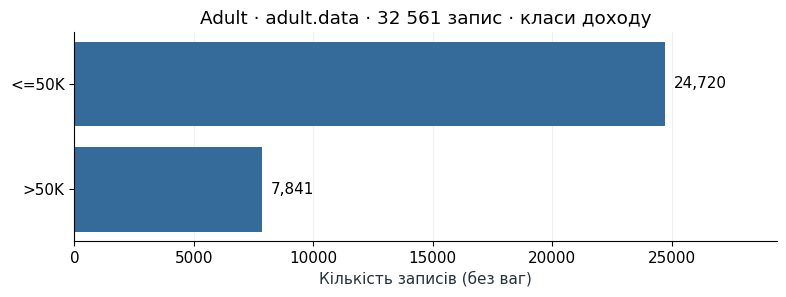

In [10]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.labelcolor": "#263238"})
labels = [row["income"] for row in results["distribution"]]
counts = [row["n_rows"] for row in results["distribution"]]
fig, ax = plt.subplots(figsize=(8, 3.1))
bars = ax.barh(labels, counts, color="#356b9a")
ax.set_xlim(0, max(counts) * 1.19)
ax.set_xlabel("Кількість записів (без ваг)")
ax.set_title("Adult · adult.data · 32 561 запис · класи доходу")
ax.invert_yaxis()
for bar, value in zip(bars, counts):
    ax.text(value + max(counts) * .015, bar.get_y() + bar.get_height()/2, f"{value:,}", va="center")
ax.grid(axis="x", alpha=.18)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [11]:
results['numeric_stats'] = run_sql('numeric_stats', """
SELECT COUNT(age) AS n_non_null, MIN(age) AS min_age,
       MAX(age) AS max_age, SUM(age) AS sum_age,
       ROUND(AVG(age), 2) AS mean_age,
       ROUND(STDDEV_SAMP(age), 2) AS sd_age,
       MIN(hours_per_week) AS min_hours, MAX(hours_per_week) AS max_hours,
       ROUND(AVG(hours_per_week), 2) AS mean_hours,
       MIN(capital_gain) AS min_capital_gain, MAX(capital_gain) AS max_capital_gain,
       SUM(capital_gain) AS sum_capital_gain
FROM hw3_adult_clean;
""")

```sql
SELECT COUNT(age) AS n_non_null, MIN(age) AS min_age,
       MAX(age) AS max_age, SUM(age) AS sum_age,
       ROUND(AVG(age), 2) AS mean_age,
       ROUND(STDDEV_SAMP(age), 2) AS sd_age,
       MIN(hours_per_week) AS min_hours, MAX(hours_per_week) AS max_hours,
       ROUND(AVG(hours_per_week), 2) AS mean_hours,
       MIN(capital_gain) AS min_capital_gain, MAX(capital_gain) AS max_capital_gain,
       SUM(capital_gain) AS sum_capital_gain
FROM hw3_adult_clean;
```

,value
metric,
n_non_null,32561
min_age,17
max_age,90
sum_age,1256257
mean_age,38.58
sd_age,13.64
min_hours,1
max_hours,99
mean_hours,40.44


Вік заповнено в усіх 32 561 записах: 17–90 років, середнє 38,58, вибіркове стандартне відхилення 13,64 року. Робочий тиждень лежить у межах 1–99 годин, середнє 40,44; `capital_gain` — 0–99 999 одиниць джерела. Середнє без аналізу форми розподілу не є достатнім критерієм аномалій, тому далі застосовано предметні межі.

### 4.5. Предметні межі й крайні значення

Перевірка застосовує межі до **staging**, до обмежень clean: вік 17–120, тиждень 1–168 годин, додатна вага, невід'ємні капітальні значення, код освіти 1–16. Це не незалежний доказ якості джерела, а перевірка обраного контракту. Додатково підраховано значення на спостережених верхніх краях; вони не видаляються автоматично.

In [12]:
results['domain_check'] = run_sql('domain_check', """
SELECT COUNT(*) FILTER (
           WHERE BTRIM(age_raw)::INTEGER NOT BETWEEN 17 AND 120
              OR BTRIM(hours_per_week_raw)::INTEGER NOT BETWEEN 1 AND 168
              OR BTRIM(fnlwgt_raw)::BIGINT <= 0
              OR BTRIM(education_num_raw)::INTEGER NOT BETWEEN 1 AND 16
              OR BTRIM(capital_gain_raw)::NUMERIC < 0
              OR BTRIM(capital_loss_raw)::NUMERIC < 0
       ) AS domain_violations,
       COUNT(*) FILTER (WHERE BTRIM(age_raw)::INTEGER = 90) AS age_90_rows,
       COUNT(*) FILTER (WHERE BTRIM(hours_per_week_raw)::INTEGER = 99) AS hours_99_rows,
       COUNT(*) FILTER (WHERE BTRIM(capital_gain_raw)::NUMERIC = 99999) AS gain_99999_rows
FROM hw3_adult_staging;
""")

```sql
SELECT COUNT(*) FILTER (
           WHERE BTRIM(age_raw)::INTEGER NOT BETWEEN 17 AND 120
              OR BTRIM(hours_per_week_raw)::INTEGER NOT BETWEEN 1 AND 168
              OR BTRIM(fnlwgt_raw)::BIGINT <= 0
              OR BTRIM(education_num_raw)::INTEGER NOT BETWEEN 1 AND 16
              OR BTRIM(capital_gain_raw)::NUMERIC < 0
              OR BTRIM(capital_loss_raw)::NUMERIC < 0
       ) AS domain_violations,
       COUNT(*) FILTER (WHERE BTRIM(age_raw)::INTEGER = 90) AS age_90_rows,
       COUNT(*) FILTER (WHERE BTRIM(hours_per_week_raw)::INTEGER = 99) AS hours_99_rows,
       COUNT(*) FILTER (WHERE BTRIM(capital_gain_raw)::NUMERIC = 99999) AS gain_99999_rows
FROM hw3_adult_staging;
```

,domain_violations,age_90_rows,hours_99_rows,gain_99999_rows
0,0,43,85,159


Порушень цих предметних меж немає. Значення 90 років, 99 годин і 99 999 у `capital_gain` залишено: вони припустимі за контрактом і самі по собі не доводять помилку. Для аналітичного pipeline варто додати прапорці крайніх значень та перевірити в джерелі можливе top-coding; ця робота не приписує їм доведений статус top-code і не виключає їх із даних.

## 5. Десять DQL/EDA-запитів

Усі запитання стосуються записів `adult.data`; частки — незважені. Поля у `SELECT` названо явно, а порядок із `LIMIT` має явний tie-breaker.

### 01. Які п’ять відомих категорій workclass мають найбільше записів?

**Business-question:** Які п’ять відомих категорій workclass мають найбільше записів?

In [13]:
results['q01'] = run_sql('q01', """
SELECT workclass, COUNT(*) AS n_rows
FROM hw3_adult_clean
WHERE workclass IS NOT NULL
GROUP BY workclass
ORDER BY n_rows DESC, workclass
LIMIT 5;
""")

```sql
SELECT workclass, COUNT(*) AS n_rows
FROM hw3_adult_clean
WHERE workclass IS NOT NULL
GROUP BY workclass
ORDER BY n_rows DESC, workclass
LIMIT 5;
```

,workclass,n_rows
0,Private,22696
1,Self-emp-not-inc,2541
2,Local-gov,2093
3,State-gov,1298
4,Self-emp-inc,1116


**Interpretation:** Найбільше записів має Private — 22 696; далі йдуть Self-emp-not-inc — 2 541, Local-gov — 2 093, State-gov — 1 298 та Self-emp-inc — 1 116. Private істотно переважає кожну наступну категорію в цьому результаті, тому загальні характеристики файлу можуть приховувати відмінності менших груп. Запит виключає невідомий workclass і показує лише п'ять категорій; це не повний розподіл усіх записів.

### 02. Як відрізняються незважені частки income >50K між категоріями освіти?

**Business-question:** Як відрізняються незважені частки income >50K між категоріями освіти?

In [14]:
results['q02'] = run_sql('q02', """
SELECT education, education_num, COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
GROUP BY education, education_num
ORDER BY education_num DESC, education;
""")

```sql
SELECT education, education_num, COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
GROUP BY education, education_num
ORDER BY education_num DESC, education;
```

,education,education_num,n_rows,high_income_rows,pct_high_income
0,Doctorate,16,413,306,74.09
1,Prof-school,15,576,423,73.44
2,Masters,14,1723,959,55.66
3,Bachelors,13,5355,2221,41.48
4,Assoc-acdm,12,1067,265,24.84
5,Assoc-voc,11,1382,361,26.12
6,Some-college,10,7291,1387,19.02
7,HS-grad,9,10501,1675,15.95
8,12th,8,433,33,7.62
9,11th,7,1175,60,5.11


**Interpretation:** Частка income >50K становить 74,09% для Doctorate (306 із 413 записів), 73,44% для Prof-school (423 із 576) та 15,95% для HS-grad (1 675 із 10 501). Найбільшу за кількістю групу HS-grad не слід плутати з групою найбільшої частки високого доходу. Це незважені асоціації в межах кожної категорії освіти, які не доводять причинного впливу освіти на дохід.

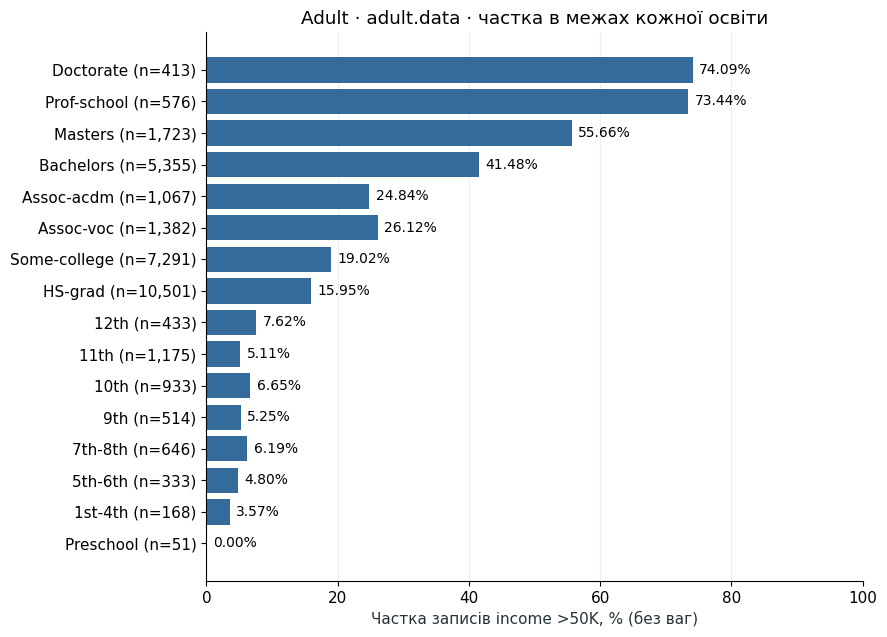

In [15]:
rows = results["q02"]
fig, ax = plt.subplots(figsize=(9, 6.5))
labels = [f"{r['education']} (n={r['n_rows']:,})" for r in rows]
values = [float(r["pct_high_income"]) for r in rows]
bars = ax.barh(labels, values, color="#356b9a")
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Частка записів income >50K, % (без ваг)")
ax.set_title("Adult · adult.data · частка в межах кожної освіти")
for bar, value in zip(bars, values):
    ax.text(value + 1, bar.get_y() + bar.get_height()/2, f"{value:.2f}%", va="center", fontsize=10)
ax.grid(axis="x", alpha=.18)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 03. Яка частка income >50K у чотирьох діапазонах годин роботи на тиждень?

**Business-question:** Яка частка income >50K у чотирьох діапазонах годин роботи на тиждень?

In [16]:
results['q03'] = run_sql('q03', """
SELECT CASE WHEN hours_per_week < 20 THEN '1: 1–19'
            WHEN hours_per_week < 40 THEN '2: 20–39'
            WHEN hours_per_week = 40 THEN '3: 40'
            ELSE '4: 41–168' END AS hours_band,
       COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
GROUP BY hours_band
ORDER BY hours_band;
""")

```sql
SELECT CASE WHEN hours_per_week < 20 THEN '1: 1–19'
            WHEN hours_per_week < 40 THEN '2: 20–39'
            WHEN hours_per_week = 40 THEN '3: 40'
            ELSE '4: 41–168' END AS hours_band,
       COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
GROUP BY hours_band
ORDER BY hours_band;
```

,hours_band,n_rows,high_income_rows,pct_high_income
0,1: 1–19,1704,117,6.87
1,2: 20–39,6059,621,10.25
2,3: 40,15217,3247,21.34
3,4: 41–168,9581,3856,40.25


**Interpretation:** Для діапазонів 1–19, 20–39, рівно 40 та 41–168 годин частки income >50K дорівнюють відповідно 6,87%, 10,25%, 21,34% та 40,25%. Найбільше записів має група рівно 40 годин — 15 217, тоді як у групі 41–168 є 9 581 запис. Остання межа є межею групування; фактичний максимум файлу — 99 годин, а відмінності часток не означають, що збільшення годин саме спричинить вищий дохід.

### 04. Які десять найрідкісніших відомих категорій native_country є у файлі?

**Business-question:** Які десять найрідкісніших відомих категорій native_country є у файлі?

In [17]:
results['q04'] = run_sql('q04', """
SELECT native_country, COUNT(*) AS n_rows
FROM hw3_adult_clean
WHERE native_country IS NOT NULL
GROUP BY native_country
ORDER BY n_rows, native_country
LIMIT 10;
""")

```sql
SELECT native_country, COUNT(*) AS n_rows
FROM hw3_adult_clean
WHERE native_country IS NOT NULL
GROUP BY native_country
ORDER BY n_rows, native_country
LIMIT 10;
```

,native_country,n_rows
0,Holand-Netherlands,1
1,Scotland,12
2,Honduras,13
3,Hungary,13
4,Outlying-US(Guam-USVI-etc),14
5,Yugoslavia,16
6,Laos,18
7,Thailand,18
8,Cambodia,19
9,Trinadad&Tobago,19


**Interpretation:** Серед відомих значень найрідкісніша категорія — Holand-Netherlands з одним записом; Scotland має 12, Honduras та Hungary — по 13. Історичні назви збережено так, як їх закодовано у джерелі, без припущень про сучасну географію. Ці малі групи описують представленість у файлі й самі по собі не обґрунтовують ні висновків про населення країн, ні автоматичного вилучення записів.

### 05. У яких категоріях workclass найбільше пропусків occupation?

**Business-question:** У яких категоріях workclass найбільше пропусків occupation?

In [18]:
results['q05'] = run_sql('q05', """
SELECT COALESCE(workclass, '[SQL NULL]') AS workclass,
       COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE occupation IS NULL) AS missing_occupation,
       ROUND(COUNT(*) FILTER (WHERE occupation IS NULL) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_missing_occupation
FROM hw3_adult_clean
GROUP BY workclass
ORDER BY missing_occupation DESC, workclass;
""")

```sql
SELECT COALESCE(workclass, '[SQL NULL]') AS workclass,
       COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE occupation IS NULL) AS missing_occupation,
       ROUND(COUNT(*) FILTER (WHERE occupation IS NULL) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_missing_occupation
FROM hw3_adult_clean
GROUP BY workclass
ORDER BY missing_occupation DESC, workclass;
```

,workclass,n_rows,missing_occupation,pct_missing_occupation
0,[SQL NULL],1836,1836,100.00
1,Never-worked,7,7,100.00
2,Federal-gov,960,0,0.00
3,Local-gov,2093,0,0.00
4,Private,22696,0,0.00
5,Self-emp-inc,1116,0,0.00
6,Self-emp-not-inc,2541,0,0.00
7,State-gov,1298,0,0.00
8,Without-pay,14,0,0.00


**Interpretation:** Усі 1 836 записів із невідомим workclass мають також пропуск occupation; ще сім пропусків occupation належать категорії Never-worked. Разом це 1 843 пропуски occupation, а в інших показаних групах їх немає. Позначка [SQL NULL] лише відображає пропуск для читача, а не вводить новий тип роботодавця; спільна поява пропусків потребує перевірки механізму збору даних.

### 06. Скільки записів віком 25–64 мають обрану вищу освіту й відомий workclass поза Never-worked та Without-pay?

**Business-question:** Скільки записів віком 25–64 мають обрану вищу освіту й відомий workclass поза Never-worked та Without-pay?

In [19]:
results['q06'] = run_sql('q06', """
SELECT COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
WHERE age BETWEEN 25 AND 64
  AND (education IN ('Bachelors', 'Masters', 'Doctorate') OR education_num = 15)
  AND workclass IS NOT NULL
  AND NOT (workclass IN ('Never-worked', 'Without-pay'));
""")

```sql
SELECT COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
WHERE age BETWEEN 25 AND 64
  AND (education IN ('Bachelors', 'Masters', 'Doctorate') OR education_num = 15)
  AND workclass IS NOT NULL
  AND NOT (workclass IN ('Never-worked', 'Without-pay'));
```

,n_rows,high_income_rows,pct_high_income
0,7083,3691,52.11


**Interpretation:** Відібрано 7 083 записи віком 25–64 із заданими категоріями освіти та відомим workclass поза Never-worked і Without-pay. З них 3 691 має income >50K, тобто 52,11% саме цієї підгрупи. Умова education_num = 15 додає Prof-school до трьох явно названих категорій, а отримана частка не є часткою для всього файлу чи населення.

### 07. Які відомі категорії occupation містять фрагмент managerial без урахування регістру?

**Business-question:** Які відомі категорії occupation містять фрагмент managerial без урахування регістру?

In [20]:
results['q07'] = run_sql('q07', """
SELECT occupation, COUNT(*) AS n_rows,
       ROUND(AVG(hours_per_week), 2) AS mean_hours
FROM hw3_adult_clean
WHERE occupation ILIKE '%managerial%'
GROUP BY occupation
ORDER BY n_rows DESC, occupation;
""")

```sql
SELECT occupation, COUNT(*) AS n_rows,
       ROUND(AVG(hours_per_week), 2) AS mean_hours
FROM hw3_adult_clean
WHERE occupation ILIKE '%managerial%'
GROUP BY occupation
ORDER BY n_rows DESC, occupation;
```

,occupation,n_rows,mean_hours
0,Exec-managerial,4066,44.99


**Interpretation:** Шаблон ILIKE '%managerial%' знайшов категорію Exec-managerial з 4 066 записами та середнім 44,99 робочої години на тиждень. Це пошук фрагмента в джерельній назві категорії без урахування регістру. Він не охоплює довільне ширше визначення управлінської роботи й не є висновком про всі професії керівників.

### 08. Скільки записів не підтверджують workclass Private, якщо включити й невідомі значення?

**Business-question:** Скільки записів не підтверджують workclass Private, якщо включити й невідомі значення?

In [21]:
results['q08'] = run_sql('q08', """
SELECT COUNT(*) AS not_confirmed_private,
       COUNT(*) FILTER (WHERE workclass IS NULL) AS unknown_workclass,
       COUNT(*) FILTER (WHERE workclass IS NOT NULL) AS known_other_workclass
FROM hw3_adult_clean
WHERE workclass IS DISTINCT FROM 'Private';
""")

```sql
SELECT COUNT(*) AS not_confirmed_private,
       COUNT(*) FILTER (WHERE workclass IS NULL) AS unknown_workclass,
       COUNT(*) FILTER (WHERE workclass IS NOT NULL) AS known_other_workclass
FROM hw3_adult_clean
WHERE workclass IS DISTINCT FROM 'Private';
```

,not_confirmed_private,unknown_workclass,known_other_workclass
0,9865,1836,8029


**Interpretation:** IS DISTINCT FROM 'Private' повертає 9 865 записів: 8 029 із відомою іншою категорією та 1 836 із невідомим workclass. Такий результат включає SQL NULL, на відміну від звичайного порівняння <>. Невідомі записи тут означають «Private не підтверджено», а не доведений факт роботи поза Private.

### 09. Які різні пари текстової категорії education та її числового коду представлені?

**Business-question:** Які різні пари текстової категорії education та її числового коду представлені?

In [22]:
results['q09'] = run_sql('q09', """
SELECT DISTINCT education_num, education
FROM hw3_adult_clean
ORDER BY education_num, education;
""")

```sql
SELECT DISTINCT education_num, education
FROM hw3_adult_clean
ORDER BY education_num, education;
```

,education_num,education
0,1,Preschool
1,2,1st-4th
2,3,5th-6th
3,4,7th-8th
4,5,9th
5,6,10th
6,7,11th
7,8,12th
8,9,HS-grad
9,10,Some-college


**Interpretation:** DISTINCT повернув 16 пар education_num та education, від 1 / Preschool до 16 / Doctorate; кожному коду в результаті відповідає одна назва. Це узгоджені два представлення рівня освіти в цьому файлі, а не два незалежні виміри. Для майбутніх features слід обґрунтовано обрати представлення, а не автоматично додавати обидві колонки як незалежну інформацію.

### 10. Як розподілені записи за наявністю додатного capital_gain чи capital_loss та міткою доходу?

**Business-question:** Як розподілені записи за наявністю додатного capital_gain чи capital_loss та міткою доходу?

In [23]:
results['q10'] = run_sql('q10', """
SELECT CASE WHEN capital_gain > 0 AND capital_loss > 0 THEN 'gain і loss'
            WHEN capital_gain > 0 THEN 'лише gain'
            WHEN capital_loss > 0 THEN 'лише loss'
            ELSE 'обидва нуль' END AS capital_group,
       COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
GROUP BY capital_group
ORDER BY n_rows DESC, capital_group;
""")

```sql
SELECT CASE WHEN capital_gain > 0 AND capital_loss > 0 THEN 'gain і loss'
            WHEN capital_gain > 0 THEN 'лише gain'
            WHEN capital_loss > 0 THEN 'лише loss'
            ELSE 'обидва нуль' END AS capital_group,
       COUNT(*) AS n_rows,
       COUNT(*) FILTER (WHERE income_gt_50k) AS high_income_rows,
       ROUND(COUNT(*) FILTER (WHERE income_gt_50k) * 100.0 / NULLIF(COUNT(*), 0), 2) AS pct_high_income
FROM hw3_adult_clean
GROUP BY capital_group
ORDER BY n_rows DESC, capital_group;
```

,capital_group,n_rows,high_income_rows,pct_high_income
0,обидва нуль,28330,5391,19.03
1,лише gain,2712,1677,61.84
2,лише loss,1519,773,50.89


**Interpretation:** Нульові capital_gain і capital_loss мають 28 330 записів, серед яких частка income >50K становить 19,03%. Для додатного лише gain це 2 712 записів і 61,84%, для додатного лише loss — 1 519 і 50,89%; група з обома додатними значеннями у виході не представлена. Ці асоціації не доводять причинності й не підтверджують придатності капітальних показників для прогнозування без окремої перевірки моменту їх доступності.

## 6. Reflection
У файлі Adult головна проблема пропусків — маркер `?` із початковим пробілом у workclass, occupation та native_country. Тому staging зберігає сирі лексеми, а SQL спочатку обрізає пробіли й лише потім формує NULL. Порожні значення та `unknown` перевіряються окремо. Повні збіги атрибутів не доводять дублювання людей: джерело не має person_id. Такі записи залишено, а технічний source_rowid позначає тільки рядок файлу.

Великі значення не видаляються автоматично. Перевірка предметних меж відокремлює порушення контракту від рідкісних, але допустимих спостережень; верхні краї потребують уточнення у власника джерела. Історичні категорії збережено без довільного перейменування. Обмеження SQL контролюють формат і допустимість, проте не гарантують правдивості вимірювання.

Для майбутньої моделі кандидатами були б вік, зайнятість, робочі години та одне представлення освіти після перевірки доступності й підготовки пропусків. income_gt_50k є target; його сирий еквівалент не можна додавати до features. source_rowid також виключається. fnlwgt — вага опитування, яку слід розглядати окремо від звичайної ознаки. Використання демографічних категорій потребувало б обґрунтування конкретною задачею та перевірки групових помилок.

Момент прогнозування не заданий, а часових міток немає. Тому відсутність temporal leakage не підтверджена; зокрема доступність capital_gain і capital_loss потрібно зіставити з горизонтом прогнозу доходу. Самої кореляції для такого рішення недостатньо.

Для pipeline потрібні версія джерела, контрольні суми, словник категорій, явні правила пропусків, стабільний ідентифікатор запису та журнал відхилених значень. Природна задача — бінарна класифікація доходу понад 50K. Тут модель не навчалася; незважений опис історичної навчальної частини не оцінює сучасне населення США.

## 7. Контроль результатів і завершення

Ці інваріанти перевіряють узгодженість завантаження та відомі незалежні контрольні значення оригінального файла. Файл `work/query-results.json` зберігає результати всіх виконаних SELECT для перевірки й відновлення пояснень.

In [24]:
assert {r["layer"]: r["n_rows"] for r in results["audit_counts"]} == {"clean": 32561, "staging": 32561}
assert results["audit_duplicates"][0] == {
    "total_rows": 32561, "distinct_record_values": 32537, "duplicate_groups": 23,
    "rows_in_duplicate_groups": 47, "excess_duplicate_rows": 24,
}
nulls = {r["column_name"]: r["clean_nulls"] for r in results["audit_null_sentinels"]}
assert nulls["workclass"] == 1836 and nulls["occupation"] == 1843 and nulls["native_country"] == 583
assert sum(v for k, v in nulls.items() if k not in {"workclass", "occupation", "native_country"}) == 0
assert all(r["raw_sql_nulls"] == 0 and r["empty_after_trim"] == 0 and r["unknown_markers"] == 0
           and r["question_marks"] == r["clean_nulls"] for r in results["audit_null_sentinels"])
rec = results["audit_reconciliation"][0]
assert rec["rows_with_any_null"] == 2399 and rec["complete_cases"] == 30162
assert rec["complete_cases"] + rec["rows_with_any_null"] == rec["total_rows"]
assert rec["high_income_rows"] == 7841 and rec["other_income_rows"] == 24720
assert rec["high_income_rows"] + rec["other_income_rows"] == rec["total_rows"]
assert results["numeric_stats"][0]["sum_age"] == 1256257
assert results["numeric_stats"][0]["sum_capital_gain"] == Decimal("35089324")
assert results["domain_check"][0]["domain_violations"] == 0
assert len(results["q09"]) == 16
for key in ("q02", "q03", "q05", "q10"):
    assert sum(r["n_rows"] for r in results[key]) == 32561, key
report = {
    "scope": "local PostgreSQL notebook run; not a Colab execution or submission",
    "server_version": version, "server_version_num": version_num,
    "source_url": SOURCE_URL, "raw_sha256": RAW_SHA256,
    "csv_sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest(),
    "all_invariants_passed": True, "results": results,
}
(WORK_DIR / "query-results.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2, default=str) + "\n", encoding="utf-8")
print("PASS: row counts, duplicate audit, 15-column NULL/sentinel audit, class reconciliation, sums, group totals.")

PASS: row counts, duplicate audit, 15-column NULL/sentinel audit, class reconciliation, sums, group totals.


Офіційні довідки: [PostgreSQL 16 COPY](https://www.postgresql.org/docs/16/sql-copy.html), [NULL-aware comparisons](https://www.postgresql.org/docs/16/functions-comparison.html), [pgserver 0.1.4](https://pypi.org/project/pgserver/0.1.4/). `IS DISTINCT FROM` у запиті 08 включає NULL на відміну від `<>`; тому невідомий workclass показано окремо від відомих інших категорій.

In [25]:
cleanup_hw3()
atexit.unregister(cleanup_hw3)
print("Окремий тимчасовий кластер PostgreSQL зупинено й прибрано.")

Окремий тимчасовий кластер PostgreSQL зупинено й прибрано.
